In [527]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torchmetrics import F1Score
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from torch.utils.data import TensorDataset, DataLoader, random_split, Dataset
import random
import copy
from torchvision import transforms
from torchvision import datasets
from PIL import Image
from torchvision.datasets import Imagenette
import torch.nn.functional as F
from torchvision import models
from torch.utils.data import Subset
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('tagsets_json')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import re
import string
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from collections import Counter
import gensim.downloader as api
import time
from torch.nn.utils.rnn import pack_padded_sequence

[nltk_data] Downloading package punkt_tab to /Users/yurab/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/yurab/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/yurab/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/yurab/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package tagsets_json to
[nltk_data]     /Users/yurab/nltk_data...
[nltk_data]   Package tagsets_json is already up-to-date!


In [335]:
data = pd.read_csv('/Users/yurab/Desktop/Python for university/Intelligent-analysis/Lab 1 (Basic classification algorithms)/gta6_fan_expectations_2026.csv')
data

,respondent_id,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,R100000,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,R100001,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,R100002,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,R100003,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,R100004,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,R105995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,R105996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,R105997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,R105998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


In [336]:
data = data.drop(['respondent_id'], axis=1)
data

,age,gender,region,primary_platform,favorite_previous_gta,years_following_gta6,primary_info_source,trailer1_times_watched,most_anticipated_feature,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,hype_change_vs_6mo_ago,overall_sentiment
0,30,Male,Europe,Undecided,GTA San Andreas,5,Reddit,13,Better driving physics,10,5,No,96.0,19,Yes,No,Yes,Same,Very Positive
1,29,Male,Europe,PC,GTA San Andreas,4,X/Twitter,15,Dual protagonists (Jason & Lucia),10,3,Yes,70.0,10,No,No,No,Same,Very Positive
2,28,Female,Europe,Xbox Series X/S,GTA V,6,YouTube,9,Story & narrative depth,7,5,Maybe,81.0,6,No,No,Yes,Increased,Positive
3,30,Male,Europe,Xbox Series X/S,GTA Vice City,8,Gaming news sites,6,Online/multiplayer mode,8,4,Yes,80.0,11,Yes,No,Yes,Increased,Very Positive
4,40,Male,Europe,PlayStation 5,GTA V,10,TikTok,8,Realistic economy & businesses,8,4,No,69.0,25,Yes,Yes,No,Same,Very Positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,Male,Asia-Pacific,PlayStation 5,GTA San Andreas,9,Official Rockstar trailer,8,Open-world Vice City map,10,3,Yes,94.0,12,Yes,No,Yes,Same,Very Positive
5996,22,Male,North America,PC,GTA V,2,Gaming news sites,11,Open-world Vice City map,10,4,Yes,108.0,25,Yes,No,Yes,Increased,Very Positive
5997,36,Male,North America,PlayStation 5,GTA IV,1,TikTok,4,Deeper character customization,8,3,Yes,68.0,17,Yes,No,Yes,Increased,Very Positive
5998,13,Non-binary,Europe,PlayStation 5,GTA Vice City,1,X/Twitter,5,Open-world Vice City map,7,2,Yes,43.0,12,Yes,No,Yes,Same,Positive


In [337]:
data['gender'] = data['gender'].where(data['gender'].isin(['Male', 'Female']), 'Non-binary')
mean = data['willingness_to_pay_usd'].mean()
data['willingness_to_pay_usd'] = data['willingness_to_pay_usd'].fillna(int(mean))
data = pd.get_dummies(data, columns=['gender', 'region', 'primary_platform', 'favorite_previous_gta', 'primary_info_source', 'most_anticipated_feature'], dtype=int)
preorder = {'No': 0, 'Maybe': 1, 'Yes': 2}
hype_change = {'Decreased': 0, 'Same': 1, 'Increased': 2}
sentiment = {'Neutral/Cautious': 0, 'Positive': 1, 'Very Positive': 2}
data['preorder_intent'] = data['preorder_intent'].map(preorder)
data['hype_change_vs_6mo_ago'] = data['hype_change_vs_6mo_ago'].map(hype_change)
data['overall_sentiment'] = data['overall_sentiment'].map(sentiment)
array = ['expects_release_delay', 'worried_about_price', 'follows_rockstar_socials']
for i in array:
    data[i] = data[i].astype(object)
    for j in range(len(data[i])):
        if data.loc[j, i] == 'Yes':
            data.loc[j, i] = 1
        else:
            data.loc[j, i] = 0
data

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,preorder_intent,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,0,96.0,19,1,0,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,2,70.0,10,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,1,81.0,6,0,0,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,2,80.0,11,1,0,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,0,69.0,25,1,1,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,2,94.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,2,108.0,25,1,0,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,2,68.0,17,1,0,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,2,43.0,12,1,0,...,0,0,0,0,0,0,0,1,0,0


In [338]:
X = data.drop('preorder_intent', axis=1)
X

,age,years_following_gta6,trailer1_times_watched,hype_score_1to10,confidence_rockstar_delivers_1to5,willingness_to_pay_usd,expected_firstweek_hours,expects_release_delay,worried_about_price,follows_rockstar_socials,...,most_anticipated_feature_Better driving physics,most_anticipated_feature_Deeper character customization,most_anticipated_feature_Dual protagonists (Jason & Lucia),most_anticipated_feature_Graphics & ray tracing,most_anticipated_feature_Improved police/AI systems,most_anticipated_feature_Map size & exploration,most_anticipated_feature_Online/multiplayer mode,most_anticipated_feature_Open-world Vice City map,most_anticipated_feature_Realistic economy & businesses,most_anticipated_feature_Story & narrative depth
0,30,5,13,10,5,96.0,19,1,0,1,...,1,0,0,0,0,0,0,0,0,0
1,29,4,15,10,3,70.0,10,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,28,6,9,7,5,81.0,6,0,0,1,...,0,0,0,0,0,0,0,0,0,1
3,30,8,6,8,4,80.0,11,1,0,1,...,0,0,0,0,0,0,1,0,0,0
4,40,10,8,8,4,69.0,25,1,1,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,15,9,8,10,3,94.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5996,22,2,11,10,4,108.0,25,1,0,1,...,0,0,0,0,0,0,0,1,0,0
5997,36,1,4,8,3,68.0,17,1,0,1,...,0,1,0,0,0,0,0,0,0,0
5998,13,1,5,7,2,43.0,12,1,0,1,...,0,0,0,0,0,0,0,1,0,0


In [339]:
Y = data['preorder_intent']
Y

0       0
1       2
2       1
3       2
4       0
       ..
5995    2
5996    2
5997    2
5998    2
5999    2
Name: preorder_intent, Length: 6000, dtype: int64

In [340]:
X = X.to_numpy()
Y = Y.to_numpy()

In [341]:
X

array([[30, 5, 13, ..., 0, 0, 0],
       [29, 4, 15, ..., 0, 0, 0],
       [28, 6, 9, ..., 0, 0, 1],
       ...,
       [36, 1, 4, ..., 0, 0, 0],
       [13, 1, 5, ..., 1, 0, 0],
       [20, 8, 11, ..., 0, 0, 0]], shape=(6000, 51), dtype=object)

In [342]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, train_size=0.8, random_state=42, stratify=Y)

In [343]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(4800, 51)
(1200, 51)
(4800,)
(1200,)


In [344]:
# Масштабирование только числовых признаков.
# Бинарные признаки (0 и 1) оставляем без изменений.

def scale_data(X_fit, X_apply):
    X_fit = X_fit.copy()
    X_apply = X_apply.copy()

    binary_mask = np.all(np.isin(X_fit, [0, 1]), axis=0)
    numeric_mask = ~binary_mask

    scaler = StandardScaler()

    if numeric_mask.any():
        X_fit[:, numeric_mask] = scaler.fit_transform(X_fit[:, numeric_mask])
        X_apply[:, numeric_mask] = scaler.transform(X_apply[:, numeric_mask])

    return X_fit, X_apply


X_train_scaled, X_test_scaled = scale_data(X_train, X_test)

In [345]:
np.random.seed(42)
torch.manual_seed(42)

In [346]:
device = torch.device("mps" if torch.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


In [347]:
X_train = torch.from_numpy(X_train_scaled.astype(np.float32))
X_test = torch.from_numpy(X_test_scaled.astype(np.float32))
y_train = torch.from_numpy(y_train.astype(np.int64))
y_test = torch.from_numpy(y_test.astype(np.int64))

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

In [348]:
train_dataset = TensorDataset(X_train, y_train)
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=generator)

train_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=generator)

In [349]:
class Classification(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(51, 64)
        self.act1 = nn.ReLU()
        self.hidden2 = nn.Linear(64, 32)
        self.act2 = nn.ReLU()
        self.output = nn.Linear(32, 3)

    def forward(self, x):
        x = self.act1(self.hidden1(x))
        x = self.act2(self.hidden2(x))
        x = self.output(x)
        return x

In [350]:
model = Classification().to(device=device)
model

Classification(
  (hidden1): Linear(in_features=51, out_features=64, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=32, out_features=3, bias=True)
)

In [351]:
criterion = nn.CrossEntropyLoss() 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [352]:
epochs = 100
patience = 5  
best_val_loss = float('inf')
epochs_no_improve = 0
train_loss_history = []
val_loss_history = []
best_model = None
bet_epoch = 0
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    
    # --- validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            val_loss += loss.item()
    val_loss /= len(test_loader)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_epoch = epoch+ 1
        best_model = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping epoch: ", epoch)
            print("Best epoch: ", best_epoch)
            break

[01] train_loss=0.9038 | val_loss=0.8336
[02] train_loss=0.8296 | val_loss=0.8287
[03] train_loss=0.8229 | val_loss=0.8264
[04] train_loss=0.8175 | val_loss=0.8270
[05] train_loss=0.8108 | val_loss=0.8277
[06] train_loss=0.8061 | val_loss=0.8282
[07] train_loss=0.7997 | val_loss=0.8338
[08] train_loss=0.7926 | val_loss=0.8356
Early stopping epoch:  7
Best epoch:  3


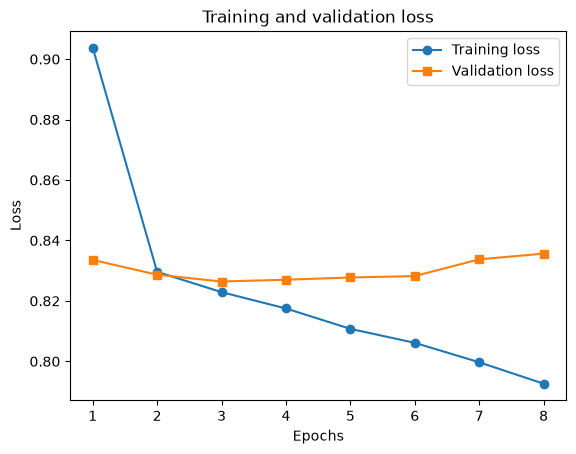

In [353]:
epochs = range(1, len(train_loss_history) + 1)
plt.plot(epochs, train_loss_history, marker='o', linestyle='-', label="Training loss")
plt.plot(epochs, val_loss_history, marker='s', linestyle='-', label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [354]:
model.load_state_dict(best_model)
model.eval()

with torch.no_grad():
    predictions = model(X_test)
    y_pred = predictions.argmax(dim=1).cpu().numpy()

y_test = y_test.cpu().numpy()

print(classification_report(y_test, y_pred,))

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.50      0.15      0.23       226
           1       0.30      0.03      0.05       219
           2       0.66      0.98      0.79       755

    accuracy                           0.65      1200
   macro avg       0.49      0.38      0.35      1200
weighted avg       0.57      0.65      0.55      1200

[[ 33  10 183]
 [ 19   6 194]
 [ 14   4 737]]


**Загальна таблиця метрик (Accuracy, Macro F1, Weighted F1)**

| Модель | Accuracy | Macro Precision | Macro Recall | Macro F1 | Weighted F1 |
|---|---|---|---|---|---|
| **Decision Tree (baseline)** | 0.57 | 0.45 | **0.45** | **0.45** | **0.58** | 
| **MLP** | **0.65** | **0.49** | 0.38 | 0.35 | 0.55 | 

---

**Confusion Matrix**

| Модель | Confusion Matrix |
|--------|------------------|
| **Decision Tree (baseline)** | `[[57, 96, 73], [55, 85, 79], [71, 144, 540]]` |
| **MLP** | `[[33, 10, 183], [19, 6, 194], [14, 4, 737]]` |

---

In [556]:
torch.manual_seed(42)
random.seed(42)

device = torch.device("mps" if torch.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


In [557]:
transform = transforms.Compose([
    transforms.Resize((160, 160), antialias=True),
    transforms.ToTensor()
])

full_train = datasets.Imagenette(root="./data", split="train", size="160px", download=True, transform=transform)
test_set = datasets.Imagenette(root="./data", split="val", size="160px", download=True, transform=transform)

print("Number of classes:", len(full_train.classes))
print("Training images:", len(full_train))
print("Test images:", len(test_set))

# розділимо train → train + val
train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size
train_set, val_set = random_split(full_train, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(val_set, batch_size=64, shuffle=False)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

Number of classes: 10
Training images: 9469
Test images: 3925


In [558]:
x, y = next(iter(train_loader))

print(x.shape)  # [64, 3, 160, 160]
print(y.shape)  # [64]

torch.Size([64, 3, 160, 160])
torch.Size([64])


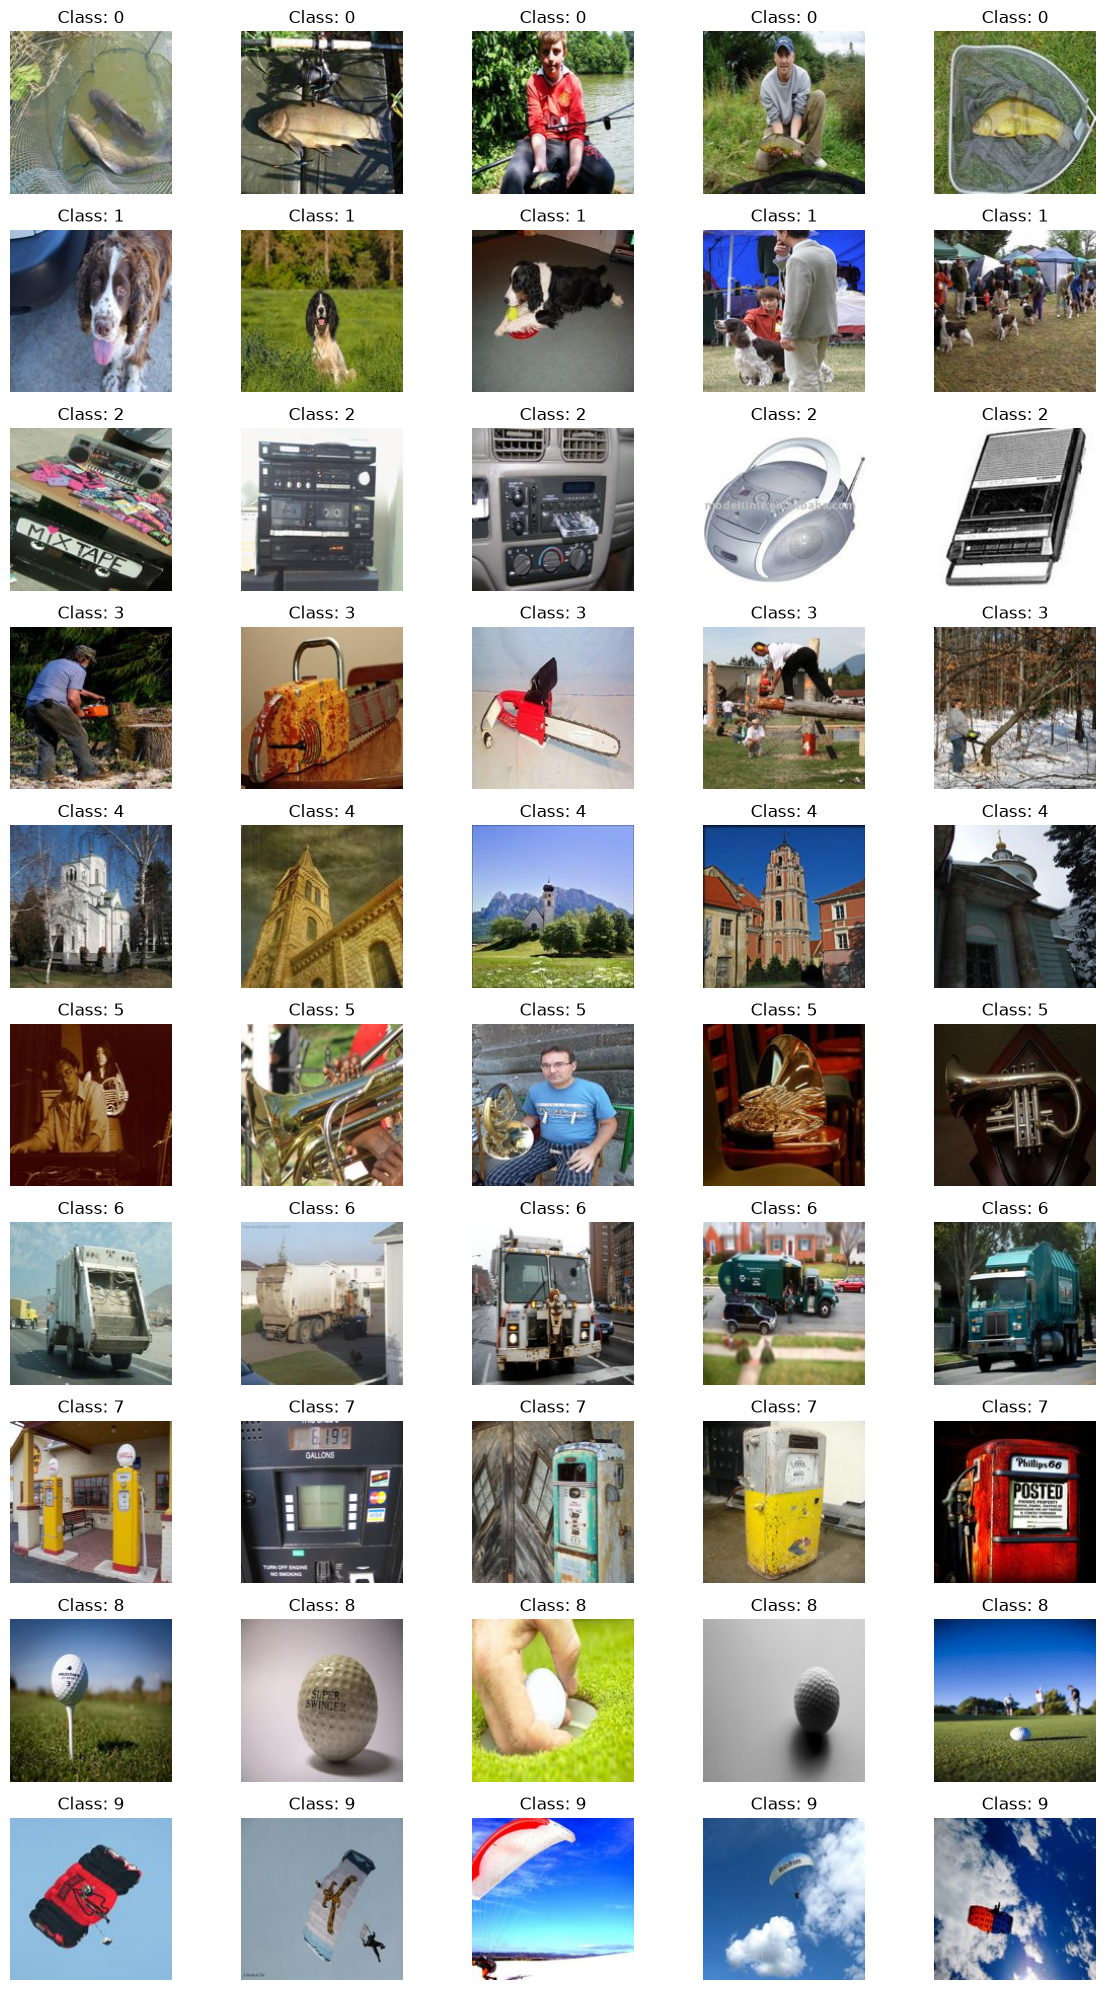

In [559]:
num_classes = 10
images_per_class = 5

class_images = {i: [] for i in range(num_classes)}

for image, label in full_train:
    if len(class_images[label]) < images_per_class:
        class_images[label].append(image)
    if all(len(images) == images_per_class for images in class_images.values()):
        break

plt.figure(figsize=(12, 20))

for class_id in range(num_classes):
    for j in range(images_per_class):
        ax = plt.subplot(num_classes, images_per_class, class_id * images_per_class + j + 1)
        image = class_images[class_id][j]
        plt.imshow(image.permute(1, 2, 0))
        plt.title(f"Class: {class_id}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [560]:
class Imagenette_CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.drop = nn.Dropout(0.3)

        self.fc1 = nn.Linear(128, 256)
        self.bn4 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.drop(F.relu(self.bn4(self.fc1(x))))
        x = self.fc2(x)

        return x

In [561]:
model = Imagenette_CNN().to(device=device)
criterion = nn.CrossEntropyLoss() 
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [562]:
epochs = 100
patience = 10  
best_val_loss = float('inf')
epochs_no_improve = 0
train_loss_history = []
val_loss_history = []
best_model = None
bet_epoch = 0
start_time = time.perf_counter()
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    
    # --- validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            val_loss += loss.item()
    val_loss /= len(valid_loader)

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)
    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_epoch = epoch+ 1
        best_model = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping epoch: ", epoch)
            print("Best epoch: ", best_epoch)
            break
elapsed_time = time.perf_counter() - start_time
print(f"Elapsed time: {elapsed_time}")

[01] train_loss=1.7546 | val_loss=1.7140
[02] train_loss=1.4437 | val_loss=1.8371
[03] train_loss=1.3036 | val_loss=2.0923
[04] train_loss=1.2137 | val_loss=1.5561
[05] train_loss=1.1279 | val_loss=1.3820
[06] train_loss=1.0639 | val_loss=1.3608
[07] train_loss=1.0186 | val_loss=1.0530
[08] train_loss=0.9657 | val_loss=1.1302
[09] train_loss=0.9397 | val_loss=1.4665
[10] train_loss=0.8966 | val_loss=1.0042
[11] train_loss=0.8599 | val_loss=1.2592
[12] train_loss=0.8382 | val_loss=1.1899
[13] train_loss=0.8282 | val_loss=1.0002
[14] train_loss=0.7772 | val_loss=0.9901
[15] train_loss=0.7594 | val_loss=1.6628
[16] train_loss=0.7556 | val_loss=1.0089
[17] train_loss=0.7237 | val_loss=1.2379
[18] train_loss=0.6983 | val_loss=1.4567
[19] train_loss=0.6708 | val_loss=1.1534
[20] train_loss=0.6619 | val_loss=0.9807
[21] train_loss=0.6311 | val_loss=1.0695
[22] train_loss=0.6386 | val_loss=1.0412
[23] train_loss=0.6116 | val_loss=1.4083
[24] train_loss=0.6046 | val_loss=1.2381
[25] train_loss=

In [563]:
model.load_state_dict(best_model)

<All keys matched successfully>

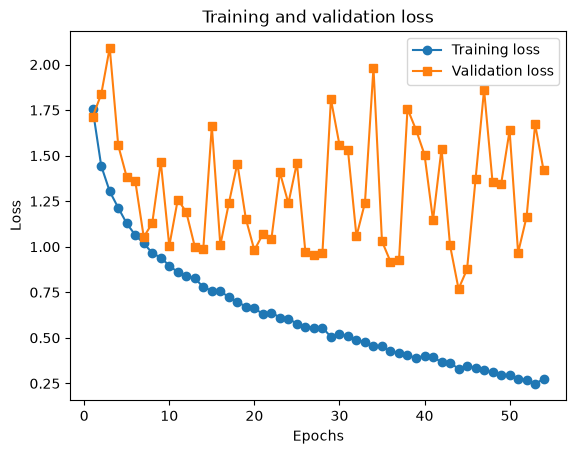

In [564]:
epochs = range(1, len(train_loss_history) + 1)
plt.plot(epochs, train_loss_history, marker='o', linestyle='-', label="Training loss")
plt.plot(epochs, val_loss_history, marker='s', linestyle='-', label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()

    total_correct = 0
    total_samples = 0

    y_test = []
    y_pred = []

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        out = model(x)
        preds = out.argmax(1)

        total_correct += (preds == y).sum().item()
        total_samples += y.size(0)

        y_test.extend(y.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


In [453]:
evaluate_accuracy(model, test_loader, device)


Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.88      0.77       387
           1       0.88      0.66      0.75       395
           2       0.76      0.70      0.73       357
           3       0.50      0.56      0.53       386
           4       0.88      0.71      0.79       409
           5       0.69      0.82      0.75       394
           6       0.83      0.72      0.77       389
           7       0.83      0.53      0.65       419
           8       0.55      0.78      0.64       399
           9       0.78      0.81      0.80       390

    accuracy                           0.72      3925
   macro avg       0.74      0.72      0.72      3925
weighted avg       0.74      0.72      0.72      3925

Confusion Matrix:
[[339   5   1   8   0  11   0   0  18   5]
 [ 18 259   4  30   3   8   3   1  64   5]
 [  6   0 251  20   2  22  12  15  27   2]
 [ 49  13   9 215   2  30   5   2  44  17]
 [  7   2   9  25 291  21  

In [466]:
resnet18 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

In [465]:
resnet_transform = transforms.Compose([
    transforms.Resize((160, 160), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

full_train_resnet = datasets.Imagenette(root="./data", split="train", size="160px", download=True, transform=resnet_transform)

test_set_resnet = datasets.Imagenette(root="./data", split="val", size="160px", download=True, transform=resnet_transform)

# Используем те же индексы, что и для первой CNN
train_set_resnet = Subset(full_train_resnet, train_set.indices)
val_set_resnet = Subset(full_train_resnet, val_set.indices)

train_loader_resnet = DataLoader(train_set_resnet, batch_size=64, shuffle=True)

valid_loader_resnet = DataLoader(val_set_resnet, batch_size=64, shuffle=False)

test_loader_resnet = DataLoader(test_set_resnet, batch_size=64, shuffle=False)

In [ ]:
# Замораживаем все слои
for p in resnet18.parameters():
    p.requires_grad = False

# Размораживаем последний блок
for p in resnet18.layer4.parameters():
    p.requires_grad = True

# Заменяем классификатор
in_features = resnet18.fc.in_features
resnet18.fc = nn.Linear(in_features, 10)

In [469]:
total = sum(p.numel() for p in resnet18.parameters())
trainable = sum(p.numel() for p in resnet18.parameters() if p.requires_grad)
print(f"total: {total:,} | trainable: {trainable:,}")

total: 11,181,642 | trainable: 5,130


In [470]:
resnet18 = resnet18.to(device)

In [ ]:
# Loss & Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([
    {"params": resnet18.layer4.parameters(), "lr": 0.0001},
    {"params": resnet18.fc.parameters(), "lr": 0.001}
])

In [ ]:
epochs = 100
patience = 10

best_val_loss = float('inf')
epochs_no_improve = 0

train_loss_history = []
val_loss_history = []

best_model = None
best_epoch = 0

for epoch in range(epochs):
    resnet18.train()
    # Замороженные слои оставляем в режиме оценки,
    # чтобы BatchNorm не обновлял статистики
    resnet18.bn1.eval()
    resnet18.layer1.eval()
    resnet18.layer2.eval()
    resnet18.layer3.eval()

    train_loss = 0.0
    train_total = 0

    for x, y in train_loader_resnet:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = resnet18(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * y.size(0)
        train_total += y.size(0)

    train_loss /= train_total

    # --- validation ---
    resnet18.eval()

    val_loss = 0.0
    val_total = 0

    with torch.no_grad():
        for x, y in valid_loader_resnet:
            x, y = x.to(device), y.to(device)
            out = resnet18(x)
            loss = criterion(out, y)
            val_loss += loss.item() * y.size(0)
            val_total += y.size(0)

    val_loss /= val_total

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_epoch = epoch+ 1
        best_model = copy.deepcopy(resnet18.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping epoch: ", epoch)
            print("Best epoch: ", best_epoch)
            break

[01] train_loss=0.4789 | val_loss=0.1761
[02] train_loss=0.1554 | val_loss=0.1351
[03] train_loss=0.1217 | val_loss=0.1173
[04] train_loss=0.1011 | val_loss=0.1094
[05] train_loss=0.0884 | val_loss=0.1060
[06] train_loss=0.0771 | val_loss=0.1000
[07] train_loss=0.0696 | val_loss=0.1011
[08] train_loss=0.0637 | val_loss=0.1007
[09] train_loss=0.0562 | val_loss=0.0984
[10] train_loss=0.0524 | val_loss=0.0985
[11] train_loss=0.0486 | val_loss=0.1006
[12] train_loss=0.0434 | val_loss=0.0982
[13] train_loss=0.0403 | val_loss=0.1026
[14] train_loss=0.0383 | val_loss=0.1009
[15] train_loss=0.0339 | val_loss=0.1022
[16] train_loss=0.0318 | val_loss=0.1041
[17] train_loss=0.0291 | val_loss=0.1046
[18] train_loss=0.0275 | val_loss=0.1037
[19] train_loss=0.0257 | val_loss=0.1041
[20] train_loss=0.0237 | val_loss=0.1028
[21] train_loss=0.0219 | val_loss=0.1060
[22] train_loss=0.0203 | val_loss=0.1093
Early stopping epoch:  21
Best epoch:  12


In [ ]:
resnet18.load_state_dict(best_model)

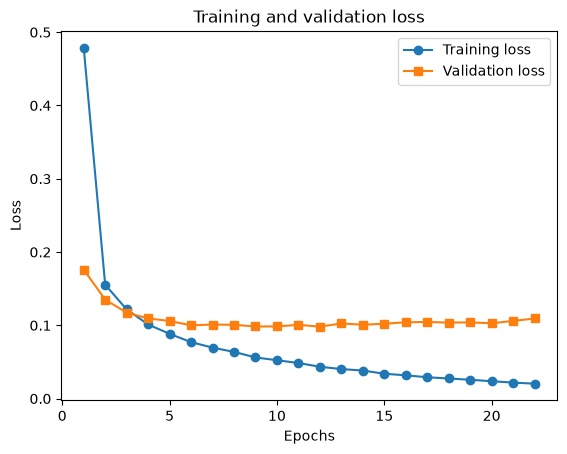

In [473]:
epochs = range(1, len(train_loss_history) + 1)
plt.plot(epochs, train_loss_history, marker='o', linestyle='-', label="Training loss")
plt.plot(epochs, val_loss_history, marker='s', linestyle='-', label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
evaluate_accuracy(resnet18, test_loader, device)


Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.88      0.77       387
           1       0.88      0.66      0.75       395
           2       0.76      0.70      0.73       357
           3       0.50      0.56      0.53       386
           4       0.88      0.71      0.79       409
           5       0.69      0.82      0.75       394
           6       0.83      0.72      0.77       389
           7       0.83      0.53      0.65       419
           8       0.55      0.78      0.64       399
           9       0.78      0.81      0.80       390

    accuracy                           0.72      3925
   macro avg       0.74      0.72      0.72      3925
weighted avg       0.74      0.72      0.72      3925

Confusion Matrix:
[[339   5   1   8   0  11   0   0  18   5]
 [ 18 259   4  30   3   8   3   1  64   5]
 [  6   0 251  20   2  22  12  15  27   2]
 [ 49  13   9 215   2  30   5   2  44  17]
 [  7   2   9  25 291  21  

In [540]:
data_nlp = pd.read_csv("/Users/yurab/Desktop/Python for university/Intelligent-analysis/Lab2 (Unsupervised Learning and Intro to NLP)/emails.csv")
data_nlp

,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1
...,...,...
5723,Subject: re : research and development charges...,0
5724,"Subject: re : receipts from visit jim , than...",0
5725,Subject: re : enron case study update wow ! a...,0
5726,"Subject: re : interest david , please , call...",0


In [541]:
stop_words = set(stopwords.words('english'))
stop_words.update(['enron', 'hou', 'ect', 'cc', 'pm', 'u', 'j', 'http', 'www', 'com', 'vince', 'kaminski'])
for i in range(len(data_nlp)):
    text = data_nlp['text'].iloc[i]
    text = re.sub(r'<.*?>', ' ', text) # Remove HTML characters and special characters
    text = re.sub(r'&\w+;', ' ', text) # -''-
    text = text.lower() # Convert to lowercase
    text = re.sub(r"^subject:.*?:", "", text) # Remove subjects
    text = re.sub(r'\s*-\s*', '', text) # Remove - between two words
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text) # Remove punctuations
    text = re.sub(r'\s{2,}', " ", text) # Remove extra space
    text = ' '.join([word for word in text.split(' ') if word not in stop_words]) # Remove stop_words
    data_nlp.loc[i, 'text'] = text
data_nlp

,text,spam
0,market full suqgestions information isoverwhe...,1
1,subject stock trading gunslinger fanny merrill...,1
2,subject unbelievable new homes made easy im wa...,1
3,626 3388090 fax 626 3388102 email ramsey gold...,1
4,subject money get software cds software compat...,1
...,...,...
5723,research development charges gpg forwarded sh...,0
5724,receipts visit jim thanks invitation visit ls...,0
5725,case study update wow day super thank much co...,0
5726,interest david please call shirley crenshaw a...,0


In [542]:
texts = data_nlp["text"].tolist()
labels = data_nlp["spam"].astype(int).to_numpy()

print(data_nlp["spam"].value_counts())

spam
0    4360
1    1368
Name: count, dtype: int64


In [543]:
X_train_val, X_test, y_train_val, y_test = train_test_split(texts,labels,test_size=0.2, random_state=42, stratify=labels)

X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=42, stratify=y_train_val)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 3665
Validation: 917
Test: 1146


In [544]:
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+", text)

PAD_TOKEN = "<PAD>" # заполнение последовательностей до одинаковой длины.
UNK_TOKEN = "<UNK>" # неизвестное слово, которого нет в словаре.

PAD_IDX = 0
UNK_IDX = 1

MAX_VOCAB_SIZE = 30000

counter = Counter()

for text in X_train:
    counter.update(tokenize(text))

vocab = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}

for word, _ in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 30000


In [545]:
MAX_LEN = 300

def encode_text(text):
    tokens = tokenize(text)

    # Преобразуем слова в индексы
    sequence = [vocab.get(word, UNK_IDX) for word in tokens]

    # Обрабатываем пустые последовательности
    if len(sequence) == 0:
        sequence = [UNK_IDX]

    # Truncation
    sequence = sequence[:MAX_LEN]

    length = len(sequence)

    # Padding
    sequence += [PAD_IDX] * (MAX_LEN - length)

    return sequence, length

In [546]:
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        encoded = [encode_text(text) for text in texts]
        self.X = torch.tensor([item[0] for item in encoded], dtype=torch.long)
        self.lengths = torch.tensor([item[1] for item in encoded], dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.lengths[idx], self.y[idx]

In [547]:
train_dataset = TextDataset(X_train, y_train)
val_dataset = TextDataset(X_val, y_val)
test_dataset = TextDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32,shuffle=True)
valid_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [548]:
x, lengths, y = next(iter(train_loader))

print("X shape:", x.shape)
print("Lengths shape:", lengths.shape)
print("Labels shape:", y.shape)

X shape: torch.Size([32, 300])
Lengths shape: torch.Size([32])
Labels shape: torch.Size([32])


In [549]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)
        self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x, lengths):
        x = self.embedding(x)
        # Игнорируем padding при обработке последовательности
        x = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(x)
        # Последнее скрытое состояние
        x = hidden[-1]
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [550]:
model = GRUClassifier(vocab_size=len(vocab), embedding_dim=100, hidden_dim=128, num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

GRUClassifier(
  (embedding): Embedding(30000, 100, padding_idx=0)
  (gru): GRU(100, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)


In [551]:
epochs = 100
patience = 10
best_val_loss = float('inf')
epochs_no_improve = 0
train_loss_history = []
val_loss_history = []
best_model = None
best_epoch = 0

start_time = time.perf_counter()
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    train_total = 0
    for x, lengths, y in train_loader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        out = model(x, lengths)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * y.size(0)
        train_total += y.size(0)

    train_loss /= train_total

    # --- validation ---
    model.eval()
    val_loss = 0.0
    val_total = 0
    with torch.no_grad():
        for x, lengths, y in valid_loader:
            x = x.to(device)
            y = y.to(device)
            out = model(x, lengths)
            loss= criterion(out, y)
            val_loss += loss.item() * y.size(0)
            val_total += y.size(0)

    val_loss /= val_total
    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")
        
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_epoch = epoch+ 1
        best_model = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping epoch: ", epoch)
            print("Best epoch: ", best_epoch)
            break
elapsed_time = time.perf_counter() - start_time
print(f"Elapsed time: {elapsed_time}")

[01] train_loss=0.3977 | val_loss=0.2357
[02] train_loss=0.1582 | val_loss=0.2155
[03] train_loss=0.0863 | val_loss=0.1398
[04] train_loss=0.0364 | val_loss=0.1298
[05] train_loss=0.0303 | val_loss=0.1438
[06] train_loss=0.0138 | val_loss=0.1289
[07] train_loss=0.0060 | val_loss=0.1330
[08] train_loss=0.0037 | val_loss=0.1388
[09] train_loss=0.0025 | val_loss=0.1648
[10] train_loss=0.0021 | val_loss=0.1406
[11] train_loss=0.0018 | val_loss=0.1676
[12] train_loss=0.0022 | val_loss=0.1715
[13] train_loss=0.0015 | val_loss=0.1699
[14] train_loss=0.0019 | val_loss=0.2082
[15] train_loss=0.0017 | val_loss=0.1889
[16] train_loss=0.0014 | val_loss=0.1739
Early stopping epoch:  15
Best epoch:  6
Elapsed time: 274.77505883402773


In [512]:
model.load_state_dict(best_model)

<All keys matched successfully>

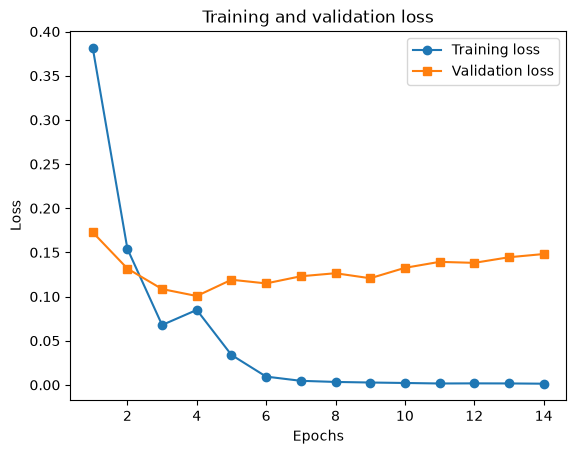

In [513]:
epochs = range(1, len(train_loss_history) + 1)
plt.plot(epochs, train_loss_history, marker='o', linestyle='-', label="Training loss")
plt.plot(epochs, val_loss_history, marker='s', linestyle='-', label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [515]:
@torch.no_grad()
def evaluate_model(model, loader, device):
    model.eval()
    y_true = []
    y_pred = []
    for x, lengths, y in loader:
        x = x.to(device)
        out = model(x, lengths)
        preds = out.argmax(1)
        y_true.extend(y.numpy())
        y_pred.extend(preds.cpu().numpy())

    print("Classification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [516]:
evaluate_model(model, test_loader, device)

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       872
           1       0.86      0.90      0.88       274

    accuracy                           0.94      1146
   macro avg       0.91      0.93      0.92      1146
weighted avg       0.94      0.94      0.94      1146

Confusion Matrix:
[[832  40]
 [ 28 246]]


In [529]:
glove = api.load("glove-wiki-gigaword-100")

print("Embedding dimension:", glove.vector_size)
print("Vocabulary size:", len(glove))

Embedding dimension: 100
Vocabulary size: 400000


In [530]:
embedding_dim = 100

torch.manual_seed(42)
initial_embedding = nn.Embedding(len(vocab), embedding_dim,padding_idx=PAD_IDX)
embedding_matrix = initial_embedding.weight.detach().cpu().numpy().copy()
hits = 0
misses = 0

for word, idx in vocab.items():
    if word in (PAD_TOKEN, UNK_TOKEN):
        continue
    if word in glove:
        embedding_matrix[idx] = glove[word]
        hits += 1
    else:
        misses += 1

embedding_matrix[PAD_IDX] = 0.0

print(f"Found pretrained vectors: {hits}")
print(f"Words without pretrained vectors: {misses}")
print(f"Coverage: {hits / (hits + misses) * 100:.2f}%")

Found pretrained vectors: 19857
Words without pretrained vectors: 10141
Coverage: 66.19%


In [531]:
glove_model = GRUClassifier(vocab_size=len(vocab),embedding_dim=100,hidden_dim=128,num_classes=2).to(device)
with torch.no_grad():
    glove_model.embedding.weight.copy_(torch.tensor(embedding_matrix, dtype=torch.float32).to(device))

In [532]:
criterion = nn.CrossEntropyLoss()
optimizer_glove = torch.optim.Adam(glove_model.parameters(),lr=0.001)

In [533]:
epochs = 100
patience = 10
best_val_loss = float('inf')
epochs_no_improve = 0
glove_train_loss_history = []
glove_val_loss_history = []
best_model = None
best_epoch = 0
start_time = time.perf_counter()
for epoch in range(epochs):
    glove_model.train()
    train_loss = 0.0
    train_total = 0
    for x, lengths, y in train_loader:
        x = x.to(device)
        y = y.to(device)
        optimizer_glove.zero_grad()
        out = glove_model(x, lengths)
        loss =criterion(out, y)
        loss.backward()
        optimizer_glove.step()
        train_loss += loss.item() * y.size(0)
        train_total += y.size(0)

    train_loss /= train_total

    # --- validation ---
    glove_model.eval()
    val_loss = 0.0
    val_total = 0
    with torch.no_grad():
        for x, lengths, y in valid_loader:
            x = x.to(device)
            y = y.to(device)
            out = glove_model(x, lengths)
            loss = criterion(out, y)
            val_loss += loss.item() * y.size(0)
            val_total += y.size(0)
    val_loss /= val_total

    glove_train_loss_history.append(train_loss)
    glove_val_loss_history.append(val_loss)

    print(f"[{epoch+1:02d}] train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")
            
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_epoch = epoch+ 1
        best_model = copy.deepcopy(model.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping epoch: ", epoch)
            print("Best epoch: ", best_epoch)
            break
elapsed_time = time.perf_counter() - start_time
print(f"Elapsed time: {elapsed_time}")

[01] train_loss=0.3694 | val_loss=0.1861
[02] train_loss=0.1390 | val_loss=0.1670
[03] train_loss=0.0776 | val_loss=0.0617
[04] train_loss=0.0265 | val_loss=0.0857
[05] train_loss=0.0143 | val_loss=0.0527
[06] train_loss=0.0627 | val_loss=0.0777
[07] train_loss=0.0166 | val_loss=0.0353
[08] train_loss=0.0053 | val_loss=0.0345
[09] train_loss=0.0040 | val_loss=0.0383
[10] train_loss=0.0023 | val_loss=0.0413
[11] train_loss=0.0025 | val_loss=0.0477
[12] train_loss=0.0031 | val_loss=0.0468
[13] train_loss=0.0014 | val_loss=0.0497
[14] train_loss=0.0014 | val_loss=0.0539
[15] train_loss=0.0011 | val_loss=0.0566
[16] train_loss=0.0013 | val_loss=0.0559
[17] train_loss=0.0013 | val_loss=0.0583
[18] train_loss=0.0015 | val_loss=0.0658
Early stopping epoch:  17
Best epoch:  8
Elapsed time: 310.757744374976


In [534]:
glove_model.load_state_dict(best_model)

<All keys matched successfully>

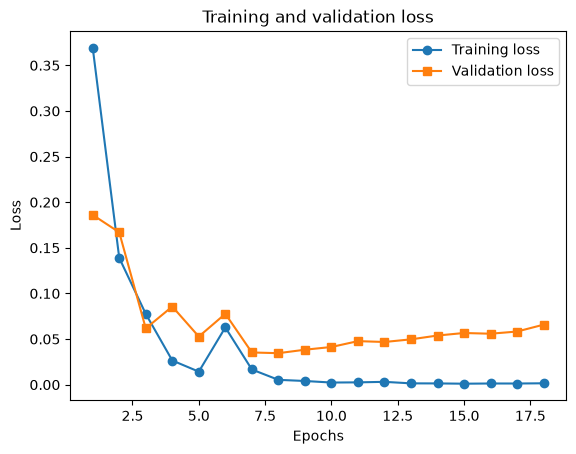

In [539]:
epochs = range(1, len(glove_train_loss_history) + 1)
plt.plot(epochs, glove_train_loss_history, marker='o', linestyle='-', label="Training loss")
plt.plot(epochs, glove_val_loss_history, marker='s', linestyle='-', label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [536]:
evaluate_model(glove_model, test_loader, device)

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       872
           1       0.86      0.90      0.88       274

    accuracy                           0.94      1146
   macro avg       0.91      0.93      0.92      1146
weighted avg       0.94      0.94      0.94      1146

Confusion Matrix:
[[832  40]
 [ 28 246]]
